H4 investigates potential indicators of selection bias in guest reviews collected from Gea and Pelagos House. It examines rating distributions, sentiment polarity, geographical representation, and differences between hotels

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt

gea = pd.read_excel("Gea_Feature_Engineering.xlsx")
pelagos = pd.read_excel("Pelagos_Feature_Engineering.xlsx")

print("Gea")
print("Shape:", gea.shape)
print("Columns:", gea.columns.tolist())
print("\nPelagos")
print("Shape:", pelagos.shape)
print("Columns:", pelagos.columns.tolist())

for name, df in [("Gea", gea), ("Pelagos", pelagos)]:
    ratings = pd.to_numeric(df["Rating"], errors="coerce").dropna()
    extreme = ratings.isin([1, 5]).sum()
    moderate = ratings.isin([2, 3, 4]).sum()

    total = len(ratings)
    print(f"\n{name}")
    print(f"Valid ratings: {total}")
    if total > 0:
        print(f"Extreme ratings(1 or 5): {extreme} ({extreme/total*100:.2f}%)")
        print(f"Moderate ratings (2, 3, 4): {moderate} ({moderate/total*100:.2f}%)")

Gea
Shape: (249, 35)
Columns: ['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommended', 'Response', 'Review Link', 'Ticket', 'External ID', 'Language', 'Author', 'Author Location', 'Review ID', 'Response Submitted Date', 'Response Posted Date', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26', 'Review_Text', 'Review_Length', 'Short_Review', 'Satisfaction_Category', 'Review_Word_Count', 'Location_Clean', 'Guest_Country', 'Guest_Region']

Pelagos
Shape: (878, 34)
Columns: ['Hotel', 'Review Site', 'Revinate Collected Date', 'Review Date', 'Rating', 'Review Title', 'Review', 'Subrating: Cleanliness', 'Subrating: Location', 'Subrating: Rooms', 'Subrating: Service', 'Subrating: Value', 'Subrating: Sleep Quality', 'Recommended', 'Response', 'Review Link', 'Ticket', 'External ID', 'Language', 'Author', 

In [10]:
for name, df in [("Gea", gea), ("Pelagos", pelagos)]:
    ratings = pd.to_numeric(
        df["Rating"], errors="coerce"
    ).dropna()

    print(f"\n{name} - Rating Verification")
    print("Minimum rating:", ratings.min())
    print("Maximum rating:", ratings.max())
    print("\nRating Frequencies:")
    print(ratings.value_counts().sort_index())

    unclassified = ratings[
        ~ratings.isin([1, 2, 3, 4, 5])
    ]
    print("\nRating outside exact 1-5 integers:")
    print(unclassified.value_counts().sort_index())


Gea - Rating Verification
Minimum rating: 0.5
Maximum rating: 5.0

Rating Frequencies:
Rating
0.5      1
1.0      3
2.5      1
3.0      4
3.5      4
4.0     23
4.5      5
5.0    200
Name: count, dtype: int64

Rating outside exact 1-5 integers:
Rating
0.5    1
2.5    1
3.5    4
4.5    5
Name: count, dtype: int64

Pelagos - Rating Verification
Minimum rating: 1.0
Maximum rating: 5.0

Rating Frequencies:
Rating
1.0     25
2.0     13
2.5      2
3.0     23
3.5      6
3.8      1
4.0     50
4.3      1
4.4      3
4.5     21
4.6      3
4.8      4
5.0    724
Name: count, dtype: int64

Rating outside exact 1-5 integers:
Rating
2.5     2
3.5     6
3.8     1
4.3     1
4.4     3
4.5    21
4.6     3
4.8     4
Name: count, dtype: int64


In [23]:
results = []

for name, df in [("Gea", gea), ("Pelagos", pelagos)]:
    ratings = pd.to_numeric(
        df["Rating"], errors="coerce"
    ).dropna()

    categories = np.select(
        [
            ratings <= 2,
            (ratings > 2) & (ratings < 4),
            (ratings >= 4) & (ratings <= 5)
        ],
        ["Low", "Moderate", "High"],
        default="Invaid"
    )
    counts = pd.Series(categories).value_counts()

    for category in ["Low", "Moderate", "High"]:
        count = counts.get(category, 0)

        results.append({
            "Hotel": name,
            "Rating Category": category,
            "Count": count,
            "Percentage": count / len(ratings) * 100
        })
        
rating_summary = pd.DataFrame(results)
print(rating_summary.round(2))

     Hotel Rating Category  Count  Percentage
0      Gea             Low      4        1.66
1      Gea        Moderate      9        3.73
2      Gea            High    228       94.61
3  Pelagos             Low     38        4.34
4  Pelagos        Moderate     32        3.65
5  Pelagos            High    806       92.01


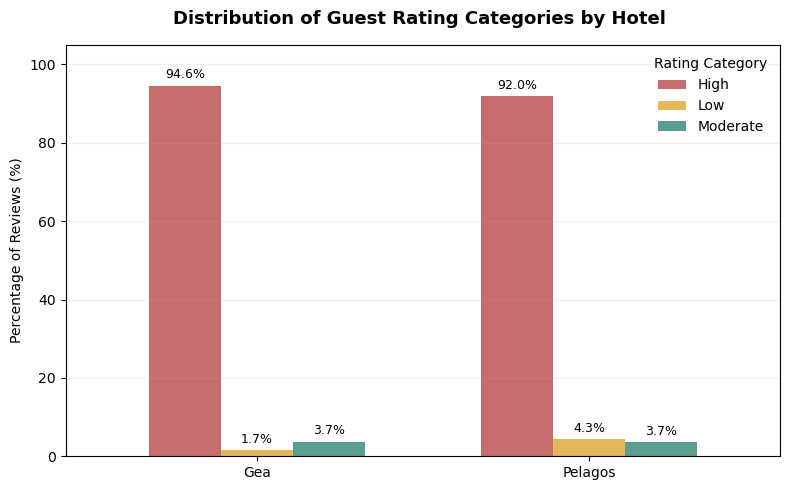

In [28]:
pivot = rating_summary.pivot(
    index="Hotel",
    columns="Rating Category",
    values="Percentage"

)

ax = pivot.plot(
    kind="bar",
    figsize=(8,5),
    color=["#C76D6D", "#E5B65C", "#5A9E91"],
    width=0.65
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )
plt.title(
    "Distribution of Guest Rating Categories by Hotel ",
     fontsize=13,
     fontweight="bold",
     pad=15
)

plt.xlabel("")
plt.ylabel("Percentage of Reviews (%)")
plt.xticks(rotation=0)
plt.ylim(0, 105)
plt.legend(title="Rating Category", frameon=False)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    "H4_Rating_Distribution_Comparisoon.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
    

In [29]:
# Creating contingency table using counts
contingency_table = rating_summary.pivot(
    index="Hotel",
    columns="Rating Category",
    values="Count"
)

contingency_table = contingency_table.reindex(
    index=["Gea", "Pelagos"],
    columns=["Low", "Moderate", "High"]
)

print("Observed Frequencies:")
print(contingency_table)

# Performing chi-square test
chi2, p, dof, expected = chi2_contingency(
    contingency_table
)

print("\nChi-Square Test Results:")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4f}")

# Check expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("\nExpected Frequencies:")
print(expected_df.round(2))

print("\nCells with expected frequency below 5:",
      (expected < 5).sum())

n = contingency_table.to_numpy().sum()
cramers_v = np.sqrt(
    chi2 / (n * min(contingency_table.shape[0]-1,
                    contingency_table.shape[1]-1))
)

print(f"\nCramer's V: {cramers_v:.4f}")

Observed Frequencies:
Rating Category  Low  Moderate  High
Hotel                               
Gea                4         9   228
Pelagos           38        32   806

Chi-Square Test Results:
Chi-square statistic: 3.7464
Degrees of freedom: 2
P-value: 0.1536

Expected Frequencies:
Rating Category    Low  Moderate    High
Hotel                                   
Gea               9.06      8.85  223.09
Pelagos          32.94     32.15  810.91

Cells with expected frequency below 5: 0

Cramer's V: 0.0579


In [35]:
geo_results = []
for name, df in [("Gea", gea), ("Pelagos", pelagos)]:
    total = len(df)
    for variable in ["Guest_Country", "Guest_Region"]:
        values = df[variable].astype("string").str.strip()
        missing = (
            values.isna()
            | values.str.lower().isin([
                "unknown", "nan", "none", "n/a", ""
            ]).fillna(False)
        )

        missing_count = int(missing.sum())
        known_count = total - missing_count

        geo_results.append({
            "Hotel": name,
            "Variable": variable,
            "Total Reviews": total,
            "Known": known_count,
            "Missing/Unknown": missing_count,
            "Missing (%)": round(
                missing_count / total * 100, 2
            )
       })

geo_summary = pd.DataFrame(geo_results)

print("H4: Geographical Data Completeness")
print(geo_summary.to_string(index=False))

H4: Geographical Data Completeness
  Hotel      Variable  Total Reviews  Known  Missing/Unknown  Missing (%)
    Gea Guest_Country            249     94              155        62.25
    Gea  Guest_Region            249     94              155        62.25
Pelagos Guest_Country            878    245              633        72.10
Pelagos  Guest_Region            878    244              634        72.21


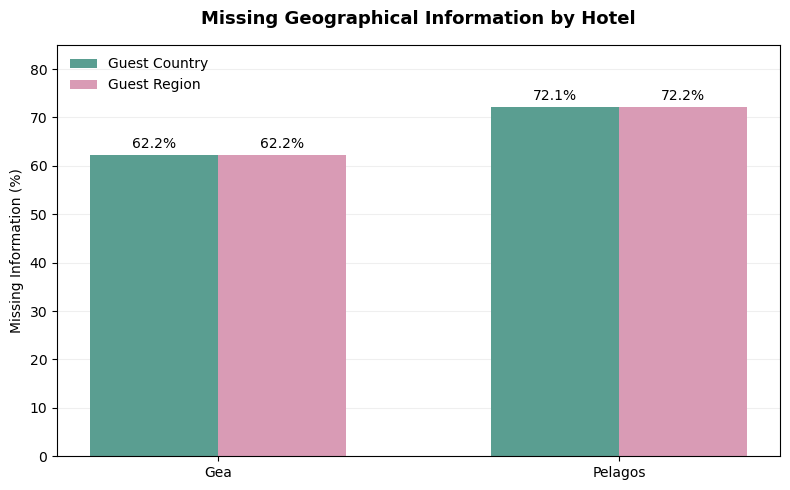

In [36]:
geo_pivot = geo_summary.pivot(
    index="Hotel",
    columns="Variable",
    values="Missing (%)"
)

geo_pivot = geo_pivot.reindex(
    index=["Gea", "Pelagos"],
    columns=["Guest_Country", "Guest_Region"]
)

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(geo_pivot.index))
width = 0.32

bars1 = ax.bar(
    x - width/2,
    geo_pivot["Guest_Country"],
    width,
    label="Guest Country",
    color="#5A9E91"
)

bars2 = ax.bar(
    x + width/2,
    geo_pivot["Guest_Region"],
    width,
    label="Guest Region",
    color="#D99BB5"
)

ax.bar_label(bars1, fmt="%.1f%%", padding=3)
ax.bar_label(bars2, fmt="%.1f%%", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(geo_pivot.index)
ax.set_ylabel("Missing Information (%)")
ax.set_ylim(0, 85)

ax.set_title(
    "Missing Geographical Information by Hotel",
    fontsize=13,
    fontweight="bold",
    pad=15
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "H4_Geographical_Missing_Data.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
country_data = geo_summary[
    geo_summary["Variable"] == "Guest_Country"
]

# Create contingency table
geo_table = country_data.set_index("Hotel")[
    ["Known", "Missing/Unknown"]
].reindex(["Gea", "Pelagos"])

print("Observed Frequencies:")
print(geo_table)

# Perform chi-square test
chi2, p, dof, expected = chi2_contingency(
    geo_table,
    correction=False
)

print("\nChi-Square Test Results:")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4f}")

# Check expected frequencies
print("\nExpected Frequencies:")
print(pd.DataFrame(
    expected,
    index=geo_table.index,
    columns=geo_table.columns
).round(2))

print("\nCells with expected frequency below 5:",
      (expected < 5).sum())

# Calculate Cramer's V
n = geo_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(geo_table.shape[0] - 1,
                     geo_table.shape[1] - 1))
)

print(f"\nCramer's V: {cramers_v:.4f}")

Observed Frequencies:
         Known  Missing/Unknown
Hotel                          
Gea         94              155
Pelagos    245              633

Chi-Square Test Results:
Chi-square statistic: 8.9428
Degrees of freedom: 1
P-value: 0.0028

Expected Frequencies:
         Known  Missing/Unknown
Hotel                          
Gea       74.9            174.1
Pelagos  264.1            613.9

Cells with expected frequency below 5: 0

Cramer's V: 0.0891


In [38]:
results = []

for hotel, df in [("Gea", gea), ("Pelagos", pelagos)]:
    ratings = pd.to_numeric(df["Rating"], errors="coerce")
    ratings = ratings[ratings.between(1, 5)]

    extreme = ratings.isin([1, 5])
    moderate = ~extreme

    results.append({
        "Hotel": hotel,
        "Valid Ratings": len(ratings),
        "Extreme Ratings": extreme.sum(),
        "Non-Extreme Ratings": moderate.sum(),
        "Extreme (%)": round(extreme.mean() * 100, 2),
        "Non-Extreme (%)": round(moderate.mean() * 100, 2)
    })

extremity_summary = pd.DataFrame(results)

print("H4: Rating Extremity Analysis")
print(extremity_summary.to_string(index=False))

table = extremity_summary[
    ["Extreme Ratings", "Non-Extreme Ratings"]
].to_numpy()

chi2, p, dof, expected = chi2_contingency(table)

n = table.sum()
cramers_v = np.sqrt(
    chi2 / (n * min(table.shape[0]-1, table.shape[1]-1))
)

print("\nChi-Square Test Results")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p:.4f}")
print(f"Cramer's V: {cramers_v:.4f}")
print(f"Expected frequencies below 5: {(expected < 5).sum()}")

if p < 0.05:
    print("Reject H0: Rating extremity differs significantly between hotels.")
else:
    print("Fail to reject H0: No statistically significant difference detected.")

H4: Rating Extremity Analysis
  Hotel  Valid Ratings  Extreme Ratings  Non-Extreme Ratings  Extreme (%)  Non-Extreme (%)
    Gea            240              203                   37        84.58            15.42
Pelagos            876              749                  127        85.50            14.50

Chi-Square Test Results
Chi-square statistic: 0.0642
Degrees of freedom: 1
P-value: 0.8000
Cramer's V: 0.0076
Expected frequencies below 5: 0
Fail to reject H0: No statistically significant difference detected.


  Hotel  Negative (1)  Positive (5)  Other Ratings  Negative (%)  Positive (%)
    Gea             3           200             37          1.25         83.33
Pelagos            25           724            127          2.85         82.65


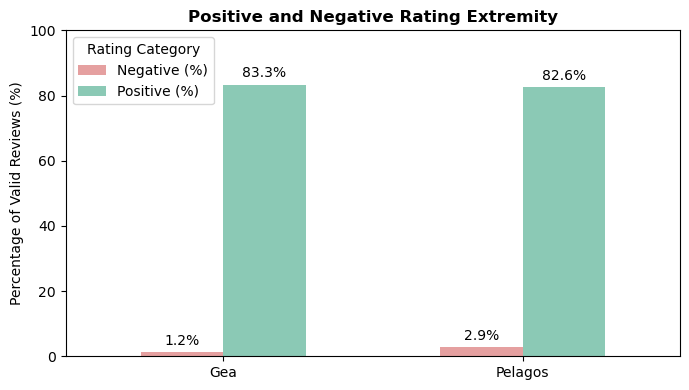

In [39]:
results = []

for name, df in [("Gea", gea), ("Pelagos", pelagos)]:
    ratings = pd.to_numeric(df["Rating"], errors="coerce")
    ratings = ratings[ratings.between(1, 5)]

    results.append({
        "Hotel": name,
        "Negative (1)": (ratings == 1).sum(),
        "Positive (5)": (ratings == 5).sum(),
        "Other Ratings": (~ratings.isin([1, 5])).sum(),
        "Negative (%)": (ratings == 1).mean() * 100,
        "Positive (%)": (ratings == 5).mean() * 100
     })

extreme_detail = pd.DataFrame(results)

print(extreme_detail.round(2).to_string(index=False))

# Visualisation
ax = extreme_detail.set_index("Hotel")[
    ["Negative (%)", "Positive (%)"]
].plot(
    kind="bar",
    figsize=(7, 4),
    color=["#E5A0A0", "#8BC9B5"],
    width=0.55
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Positive and Negative Rating Extremity",
          fontsize=12, fontweight="bold")
plt.ylabel("Percentage of Valid Reviews (%)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Rating Category")
plt.tight_layout()
plt.savefig("H4_Positive_Negative_Extremity.png",
            dpi=300, bbox_inches="tight")
plt.show()